Rajoute un python path pour pouvoir importer la librairie libsigma. 

On se trouve actuellement dans le dossier notebook, on veut rajouter le dossier `work` aux python path. On peut le faire de manière relative en remontant d'un dossier `..` ou en définissant le chemin complet `/home/onyxia/work`

In [58]:
import sys 
sys.path.append("..")
# ou sys.path.append("/home/onyxia/work")
import libsigma

## Extraction des échantillons

### Exercice : Rasteriser un fichier d'échantillons vecteurs

In [59]:
import os

# define parameters
my_folder = '/home/onyxia/work/data/td_classif'
in_vector = os.path.join(my_folder, 'sample_strata.shp')
ref_image = os.path.join(my_folder, 'aumelas_orthoirc.tif')
out_image = os.path.splitext(in_vector)[0] + '_v2.tif'
field_name = 'num'  # field containing the numeric label of the classes

# for those parameters, you know how to get theses information if you had to
sptial_resolution = 0.5
xmin = 748231.0
ymin = 6273800.0
xmax = 751231.0
ymax = 6276800.0

# define command pattern to fill with paremeters
cmd_pattern = ("gdal_rasterize -a {field_name} "
               "-tr {sptial_resolution} {sptial_resolution} "
               "-te {xmin} {ymin} {xmax} {ymax} -ot Byte -of GTiff "
               "{in_vector} {out_image}")

# fill the string with the parameter thanks to format function
cmd = cmd_pattern.format(in_vector=in_vector, xmin=xmin, ymin=ymin, xmax=xmax,
                         ymax=ymax, out_image=out_image, field_name=field_name,
                         sptial_resolution=sptial_resolution)

# execute the command in the terminal
os.system(cmd)


0...10...20...30...40...50...60...70...80...90...100 - done.


0

In [60]:
import os
print(os.path.exists(out_image))


True


### Exercice : Extraire les échantillons sous une forme adequate pour scikit learn.

In [61]:
from libsigma import classification as cla


In [62]:
import os
my_folder = '/home/onyxia/work/data/td_classif'
sample_filename = os.path.join(my_folder, 'sample_strata.tif')
image_filename = os.path.join(my_folder, 'aumelas_orthoirc.tif')
X, Y, t = cla.get_samples_from_roi(image_filename, sample_filename)
print(X.shape)
print(Y.shape)

(25557, 3)
(25557, 1)


### Exercice: Entrainer un modèle et évaluer sa qualité.

In [63]:
from sklearn import tree

clf = tree.DecisionTreeClassifier(max_leaf_nodes=10)

In [64]:
# Train
clf.fit(X, Y)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,10
,min_impurity_decrease,0.0
,class_weight,None


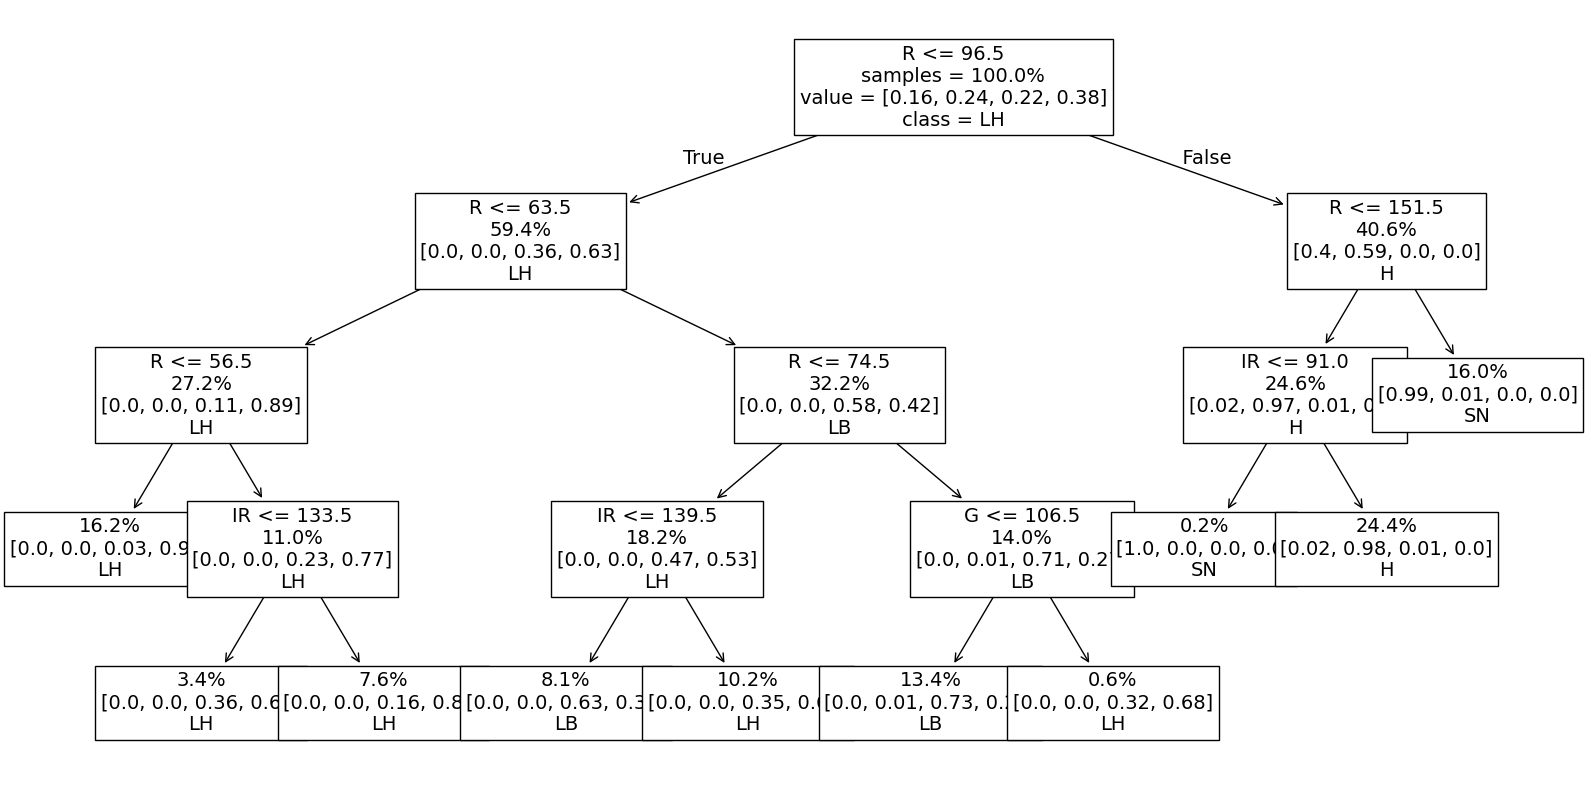

In [65]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(20,10))
my_tree = tree.plot_tree(clf, ax=ax, fontsize=14,
                         feature_names=['IR', 'R', 'G'],
                         class_names=['SN', 'H', 'LB', 'LH'],
                         label='root', impurity=False, proportion=True,
                         precision=2)

In [66]:
Y_predict = clf.predict(X)


### Exercice : Afficher une matrice de confusion avec Maplotlib.

In [67]:
from sklearn.metrics import confusion_matrix, classification_report, \
    accuracy_score
import numpy as np

# Compute the confusion matrix
cm = confusion_matrix(Y, Y_predict)

# Compute the quality metrics by classe.
report_str = classification_report(Y, Y_predict, labels=np.unique(Y))#, output_dict=True)

# Compute the overall accuracy
accuracy = accuracy_score(Y, Y_predict)

In [68]:
print(cm)
print(type(cm))

[[4082   95    0    0]
 [  46 6084   40    0]
 [   0   38 3806 1732]
 [   0   22 1631 7981]]
<class 'numpy.ndarray'>


### Exercice: Afficher les indices de qualité d'un modèle avec matplotlib.

In [69]:
from libsigma import plots

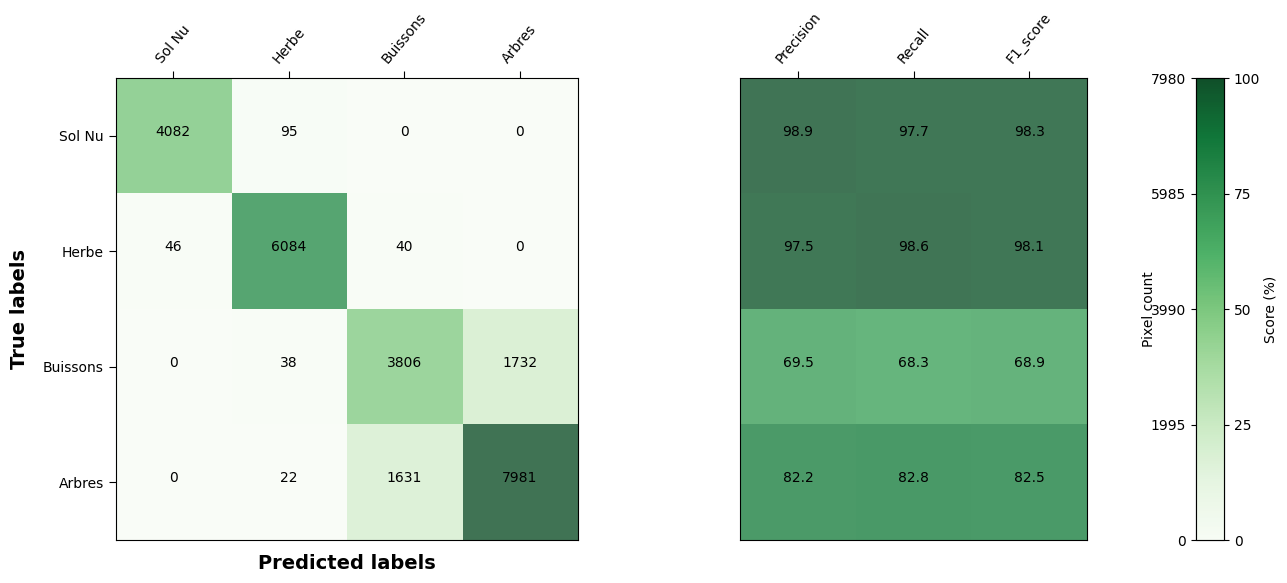

In [70]:

plots.plot_cm(cm, labels=['Sol Nu', 'Herbe', 'Buissons', 'Arbres'])

In [71]:
report = classification_report(Y, Y_predict, labels=np.unique(Y), output_dict=True)
print(report)
print()
print(report['1'])

{'1': {'precision': 0.9888565891472868, 'recall': 0.9772564041177879, 'f1-score': 0.9830222757375076, 'support': 4177.0}, '2': {'precision': 0.9751562750440775, 'recall': 0.9860615883306321, 'f1-score': 0.980578612297526, 'support': 6170.0}, '3': {'precision': 0.6949059704217637, 'recall': 0.6825681492109039, 'f1-score': 0.6886818058445671, 'support': 5576.0}, '4': {'precision': 0.8216822814784309, 'recall': 0.8284201785343575, 'f1-score': 0.8250374735101049, 'support': 9634.0}, 'accuracy': 0.8589818836326643, 'macro avg': {'precision': 0.8701502790228897, 'recall': 0.8685765800484203, 'f1-score': 0.8693300418474263, 'support': 25557.0}, 'weighted avg': {'precision': 0.8583969550700448, 'recall': 0.8589818836326643, 'f1-score': 0.8586592656734734, 'support': 25557.0}}

{'precision': 0.9888565891472868, 'recall': 0.9772564041177879, 'f1-score': 0.9830222757375076, 'support': 4177.0}


In [72]:
import pandas as pd
report_df = pd.DataFrame.from_dict(report)
report_df

,1,2,3,4,accuracy,macro avg,weighted avg
precision,0.988857,0.975156,0.694906,0.821682,0.858982,0.870150,0.858397
recall,0.977256,0.986062,0.682568,0.828420,0.858982,0.868577,0.858982
f1-score,0.983022,0.980579,0.688682,0.825037,0.858982,0.869330,0.858659
support,4177.000000,6170.000000,5576.000000,9634.000000,0.858982,25557.000000,25557.000000


In [73]:
# keep columns
report_df = report_df.loc[:, ['1', '2', '3', '4']]
# drop rows (axis=0, same as numpy)
report_df = report_df.drop(['support'], axis=0)
report_df


,1,2,3,4
precision,0.988857,0.975156,0.694906,0.821682
recall,0.977256,0.986062,0.682568,0.828420
f1-score,0.983022,0.980579,0.688682,0.825037


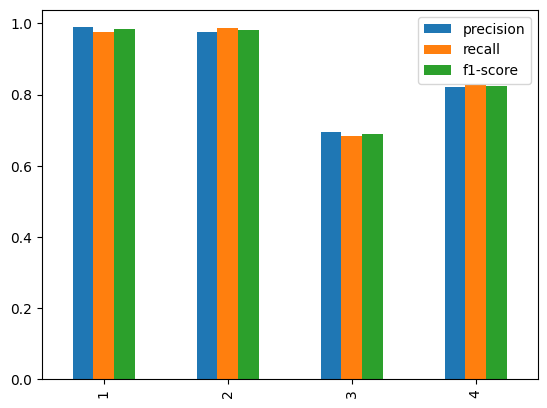

In [74]:
ax = report_df.T.plot.bar()


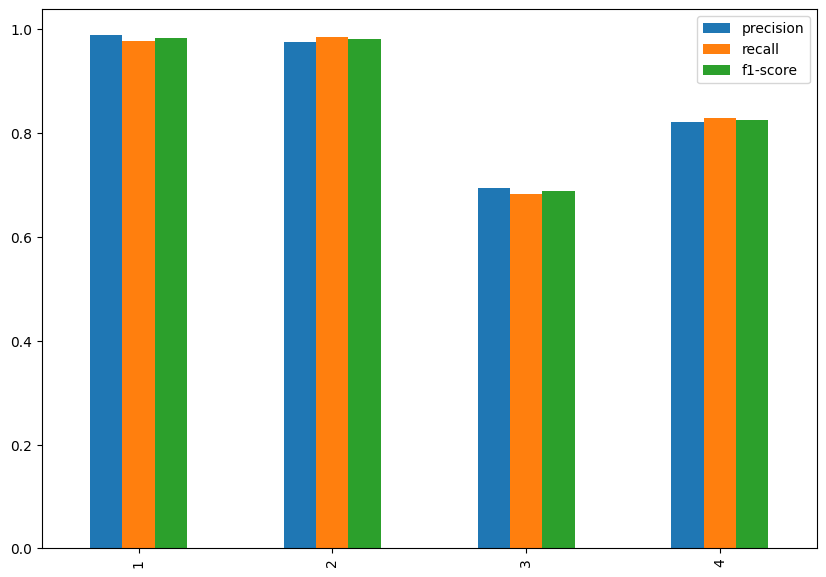

In [75]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,7))
ax = report_df.T.plot.bar(ax=ax)

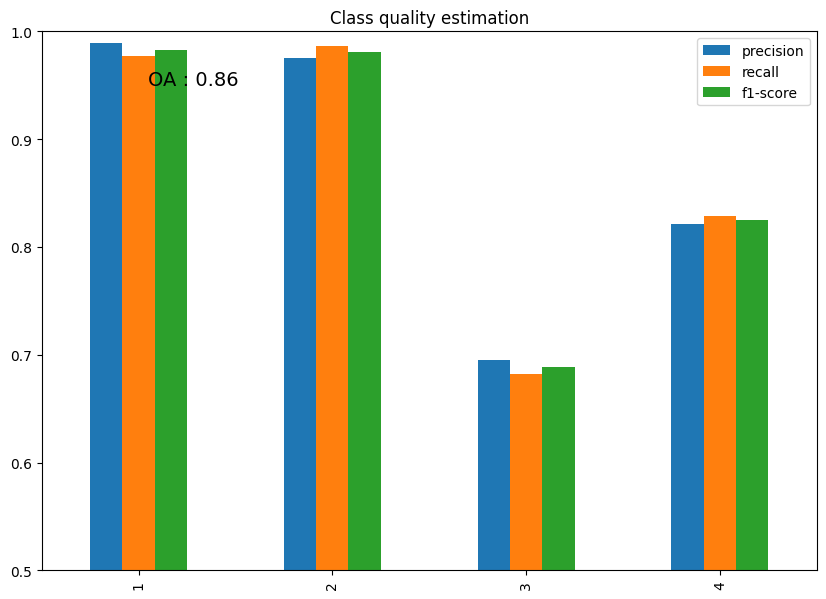

In [76]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,7))
ax = report_df.T.plot.bar(ax=ax, zorder=2)

# custom : information
ax.set_ylim(0.5, 1)
_ = ax.text(0.05, 0.95, 'OA : {:.2f}'.format(accuracy), fontsize=14)
_ = ax.set_title('Class quality estimation')

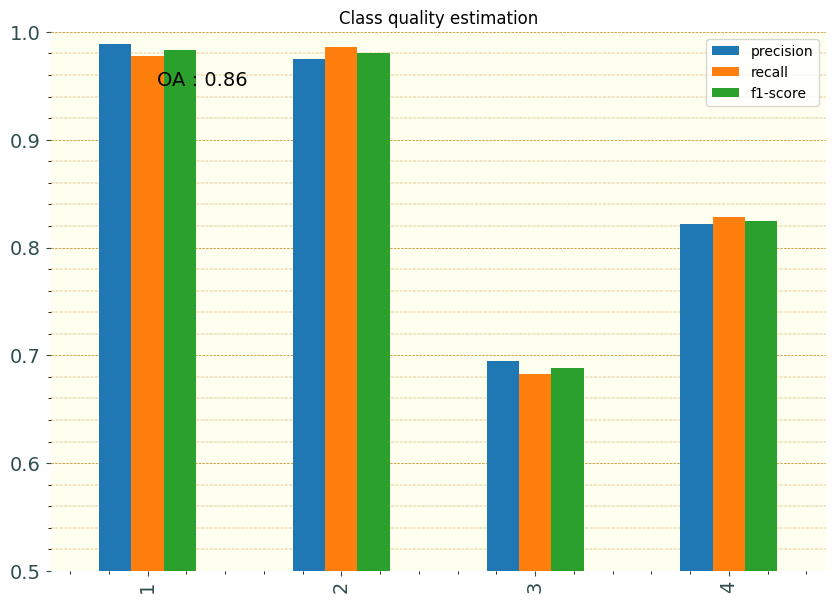

In [77]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,7))
ax = report_df.T.plot.bar(ax=ax, zorder=2)

# custom : information
ax.set_ylim(0.5, 1)
ax.text(0.05, 0.95, 'OA : {:.2f}'.format(accuracy), fontsize=14)
ax.set_title('Class quality estimation')

# custom : cuteness
# background color
ax.set_facecolor('ivory')
# labels
x_label = ax.get_xlabel()
ax.set_xlabel(x_label, fontdict={'fontname': 'Sawasdee'}, fontsize=14)
y_label = ax.get_ylabel()
ax.set_ylabel(y_label, fontdict={'fontname': 'Sawasdee'}, fontsize=14)
# borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis='x', colors='darkslategrey', labelsize=14)
ax.tick_params(axis='y', colors='darkslategrey', labelsize=14)
# grid
ax.minorticks_on()
ax.yaxis.grid(which='major', color='darkgoldenrod', linestyle='--',
                      linewidth=0.5, zorder=1)
ax.yaxis.grid(which='minor', color='darkgoldenrod', linestyle='-.',
                      linewidth=0.3, zorder=1)

{'1': {'precision': 0.9888565891472868, 'recall': 0.9772564041177879, 'f1-score': 0.9830222757375076, 'support': 4177.0}, '2': {'precision': 0.9751562750440775, 'recall': 0.9860615883306321, 'f1-score': 0.980578612297526, 'support': 6170.0}, '3': {'precision': 0.6949059704217637, 'recall': 0.6825681492109039, 'f1-score': 0.6886818058445671, 'support': 5576.0}, '4': {'precision': 0.8216822814784309, 'recall': 0.8284201785343575, 'f1-score': 0.8250374735101049, 'support': 9634.0}, 'accuracy': 0.8589818836326643, 'macro avg': {'precision': 0.8701502790228897, 'recall': 0.8685765800484203, 'f1-score': 0.8693300418474263, 'support': 25557.0}, 'weighted avg': {'precision': 0.8583969550700448, 'recall': 0.8589818836326643, 'f1-score': 0.8586592656734734, 'support': 25557.0}}

{'precision': 0.9888565891472868, 'recall': 0.9772564041177879, 'f1-score': 0.9830222757375076, 'support': 4177.0}


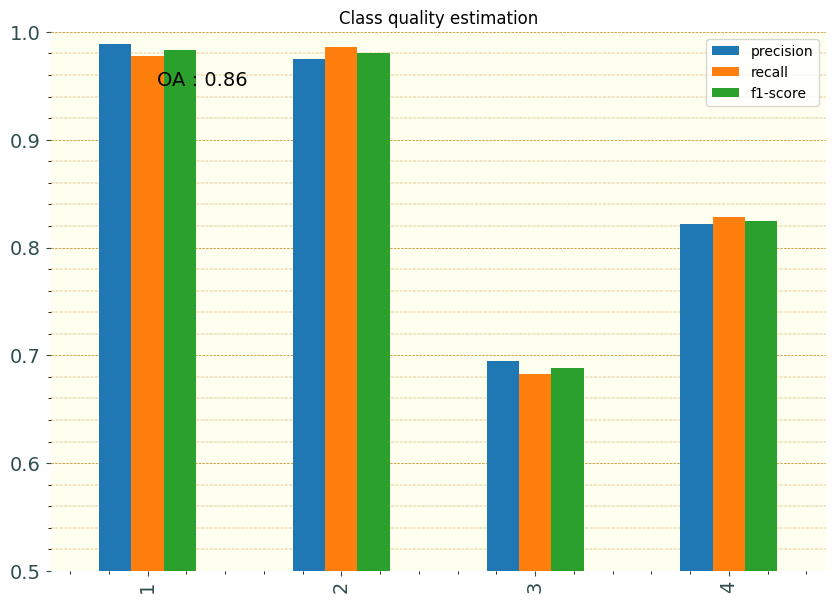

In [78]:
import pandas as pd
import matplotlib.pyplot as plt

report = classification_report(Y, Y_predict, labels=np.unique(Y), output_dict=True)
print(report)
print()
print(report['1'])

report_df = pd.DataFrame.from_dict(report)
report_df

# drop columns (axis=1, same as numpy)
report_df = report_df.loc[:, ['1', '2', '3', '4']]
# drop rows (axis=0, same as numpy)
report_df = report_df.drop(['support'], axis=0)
report_df


fig, ax = plt.subplots(figsize=(10,7))
ax = report_df.T.plot.bar(ax=ax, zorder=2)

# custom : information
ax.set_ylim(0.5, 1)
_ = ax.text(0.05, 0.95, 'OA : {:.2f}'.format(accuracy), fontsize=14)
_ = ax.set_title('Class quality estimation')

# custom : cuteness
# background color
ax.set_facecolor('ivory')
# labels
x_label = ax.get_xlabel()
ax.set_xlabel(x_label, fontdict={'fontname': 'Sawasdee'}, fontsize=14)
y_label = ax.get_ylabel()
ax.set_ylabel(y_label, fontdict={'fontname': 'Sawasdee'}, fontsize=14)
# borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis='x', colors='darkslategrey', labelsize=14)
ax.tick_params(axis='y', colors='darkslategrey', labelsize=14)
# grid
ax.minorticks_on()
ax.yaxis.grid(which='major', color='darkgoldenrod', linestyle='--',
                      linewidth=0.5, zorder=1)
ax.yaxis.grid(which='minor', color='darkgoldenrod', linestyle='-.',
                      linewidth=0.3, zorder=1)

### Exercice : Formatter une image de télédétection sous forme de tableau utilisable par scikit learn.

### Exercice : Appliquer un modèle sur l'ensemble de l'image.

In [83]:
from libsigma import classification as cla
import os

my_folder = '/home/onyxia/work/data/td_classif'
image_filename = os.path.join(my_folder, 'aumelas_orthoirc.tif')
sample_filename = image_filename
X_img, _, t_img = cla.get_samples_from_roi(image_filename, sample_filename)


In [85]:
Y_predict = clf.predict(X_img)
Y_predict.shape

(35989034,)

In [92]:
from libsigma import read_and_write as rw


In [93]:
my_folder = '/home/onyxia/work/data/td_classif'
image_filename = os.path.join(my_folder, 'aumelas_orthoirc.tif')

# Get image dimension
ds = rw.open_image(image_filename)
nb_row, nb_col, _ = rw.get_image_dimension(ds)

#initialization of the array
img = np.zeros((nb_row, nb_col, 1), dtype='uint8')
#np.Y_predict

img[t_img[0], t_img[1], 0] = Y_predict

### Exercice : Écrire le résultat d'une classification dans un fichier image.

### Exercice  : Écrire une chaîne d'instruction pour faire une classification supervisée. 